<a href="https://colab.research.google.com/github/anittajoshy2001-dot/Research_methods_tutorials/blob/main/Homework1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial homework 1: Pre-processing

In this homework, you will implement some pre-processing steps we learned in class to the California Housing dataset and verify the improvement of model predictions

In [10]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt


### Load california housing dataset

In [11]:

X, y = fetch_california_housing(return_X_y=True, as_frame=True)
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [12]:
y=y.to_frame()
y.head()

,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


### Predictions for dataset without any pre-processing

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

RF = RandomForestRegressor(random_state=42)

RF.fit(X_train,y_train)

predictions_RF = RF.predict(X_test)

mse_RF = mean_squared_error(y_test, predictions_RF)

print("RF MSE = ", mse_RF)

LinReg = LinearRegression()

LinReg.fit(X_train,y_train)

predictions_LR = LinReg.predict(X_test)

mse_LR = mean_squared_error(y_test, predictions_LR)

print("LR MSE = ", mse_LR)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RF MSE =  0.2603403202420427
LR MSE =  0.5369686543372453


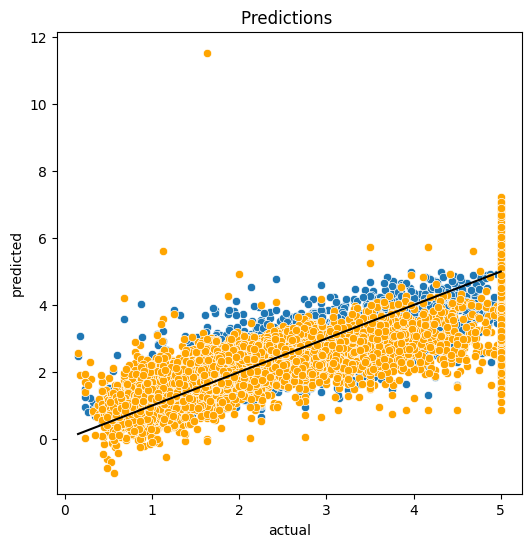

In [14]:
import seaborn as sns
# Create a dataframe to plot
df_RF = pd.DataFrame({'actual': y_test.to_numpy().flatten(), 'predicted': predictions_RF})
df_LR = pd.DataFrame({'actual': y_test.to_numpy().flatten(), 'predicted': predictions_LR.flatten()})

# Plot prediction from pre-processed dataset
plt.figure(figsize=(6, 6))
sns.scatterplot(data=df_RF, x='actual', y='predicted')
sns.scatterplot(data=df_LR, x='actual', y='predicted', color='orange')
plt.plot([min(df_RF['actual']), max(df_RF['actual'])], [min(df_RF['actual']), max(df_RF['actual'])], color='black')
plt.title('Predictions ')
plt.show()

## EXERCISE STARTS HERE

### 1) The Yeo-Johnson transform

Use the Yeo-Johnson transform on this dataset and re-fit both the Random Forest and linear regression models. Calculate the difference in MSE between predictions with the original and transformed dataset for both models.

#### 1a) Apply the Yeo-Johnson transform (to both X and y, but excluding Latitude and Longitude) and print out the parameters of the transformation (lambda) for all transformed features. Look up the PowerTransformer documentation to find out how to do this.

In [15]:
from sklearn.preprocessing import PowerTransformer

# Identify columns to transform
cols_to_transform = [col for col in X.columns if col not in ['Latitude', 'Longitude']]

# Initialize PowerTransformers
pt_X = PowerTransformer(method='yeo-johnson')
pt_y = PowerTransformer(method='yeo-johnson')

# Create copies to prevent modifying original dataframes
X_train_trans = X_train.copy()
X_test_trans = X_test.copy()

# Fit and transform X
X_train_trans[cols_to_transform] = pt_X.fit_transform(X_train[cols_to_transform])
X_test_trans[cols_to_transform] = pt_X.transform(X_test[cols_to_transform])

# Safely convert to DataFrame if they are Series, otherwise use them directly
y_train_df = y_train.to_frame() if isinstance(y_train, pd.Series) else y_train
y_test_df = y_test.to_frame() if isinstance(y_test, pd.Series) else y_test

# Fit and transform y
y_train_trans_scaled = pt_y.fit_transform(y_train_df)
y_test_trans_scaled = pt_y.transform(y_test_df)

y_train_trans = pd.DataFrame(y_train_trans_scaled, index=y_train.index, columns=y_train_df.columns)
y_test_trans = pd.DataFrame(y_test_trans_scaled, index=y_test.index, columns=y_test_df.columns)

# Print lambdas
print("X Lambdas:")
for col, lam in zip(cols_to_transform, pt_X.lambdas_):
    print(f"  {col}: {lam:.4f}")

print(f"\ny Lambda: {pt_y.lambdas_[0]:.4f}")

X Lambdas:
  MedInc: -0.1968
  HouseAge: 0.8006
  AveRooms: -0.5375
  AveBedrms: -4.1940
  Population: 0.2374
  AveOccup: -0.9000

y Lambda: -0.3666


#### 1b) Re-train the Random Forest and Linear Regression with the transformed data and compute the difference between MSEs for both models

VERY IMPORTANT: Don't forget to invert the Yeo-Johnson transformation for the target variable, so that the MSE is meaningful!

In [16]:
# 1b) Re-train and compare MSEs

# Random Forest
RF_trans = RandomForestRegressor(random_state=42)
RF_trans.fit(X_train_trans, y_train_trans.values.ravel())
pred_RF_trans_scaled = RF_trans.predict(X_test_trans)
# Invert transformation on predictions
pred_RF_trans = pt_y.inverse_transform(pred_RF_trans_scaled.reshape(-1, 1)).flatten()
mse_RF_trans = mean_squared_error(y_test, pred_RF_trans)

# Linear Regression
LR_trans = LinearRegression()
LR_trans.fit(X_train_trans, y_train_trans)
pred_LR_trans_scaled = LR_trans.predict(X_test_trans)
# Invert transformation on predictions
pred_LR_trans = pt_y.inverse_transform(pred_LR_trans_scaled).flatten()
mse_LR_trans = mean_squared_error(y_test, pred_LR_trans)

# Print Results and Differences
print(f"RF Transformed MSE: {mse_RF_trans:.6f}")
print(f"RF Original MSE:    {mse_RF:.6f}")
print(f"RF MSE Difference (Original - Transformed): {mse_RF - mse_RF_trans:.6f}\n")

print(f"LR Transformed MSE: {mse_LR_trans:.6f}")
print(f"LR Original MSE:    {mse_LR:.6f}")
print(f"LR MSE Difference (Original - Transformed): {mse_LR - mse_LR_trans:.6f}")

RF Transformed MSE: 0.266904
RF Original MSE:    0.260340
RF MSE Difference (Original - Transformed): -0.006564

LR Transformed MSE: 0.439111
LR Original MSE:    0.536969
LR MSE Difference (Original - Transformed): 0.097858


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(


### 2) Binning and enconding

Starting with the original dataset, bin the 'Latitude' column into 3 quantiles and label them as "Low", "Medium" and "High". Perform one-hot encoding for that feature and re-train both models to compute the differences in the MSEs between the original and the binned+encoded dataset. Do not apply the Yeo-Johnson transform here.

In [17]:
# 2) Binning and encoding

# Bin Latitude into 3 quantiles and label them
latitude_binned_train, bins = pd.qcut(X_train['Latitude'], q=3, labels=['Low', 'Medium', 'High'], retbins=True)
# Use the same bins for the test set
latitude_binned_test = pd.cut(X_test['Latitude'], bins=bins, labels=['Low', 'Medium', 'High'], include_lowest=True)

# One-hot encode
encoded_train = pd.get_dummies(latitude_binned_train, prefix='Lat')
encoded_test = pd.get_dummies(latitude_binned_test, prefix='Lat')

# Align columns (just in case)
encoded_train, encoded_test = encoded_train.align(encoded_test, join='left', axis=1, fill_value=0)

# Prepare new datasets
X_train_bin = X_train.drop(columns=['Latitude']).join(encoded_train)
X_test_bin = X_test.drop(columns=['Latitude']).join(encoded_test)

# Re-train models
# Random Forest
RF_bin = RandomForestRegressor(random_state=42)
RF_bin.fit(X_train_bin, y_train.values.ravel())
pred_RF_bin = RF_bin.predict(X_test_bin)
mse_RF_bin = mean_squared_error(y_test, pred_RF_bin)

# Linear Regression
LR_bin = LinearRegression()
LR_bin.fit(X_train_bin, y_train)
pred_LR_bin = LR_bin.predict(X_test_bin)
mse_LR_bin = mean_squared_error(y_test, pred_LR_bin)

# Print Results and Differences
print(f"RF Binned MSE:   {mse_RF_bin:.6f}")
print(f"RF Original MSE: {mse_RF:.6f}")
print(f"RF MSE Difference (Original - Binned): {mse_RF - mse_RF_bin:.6f}\n")

print(f"LR Binned MSE:   {mse_LR_bin:.6f}")
print(f"LR Original MSE: {mse_LR:.6f}")
print(f"LR MSE Difference (Original - Binned): {mse_LR - mse_LR_bin:.6f}")

RF Binned MSE:   0.340971
RF Original MSE: 0.260340
RF MSE Difference (Original - Binned): -0.080630

LR Binned MSE:   0.610738
LR Original MSE: 0.536969
LR MSE Difference (Original - Binned): -0.073770
